# 1. Bubble detection

Detect bubbles with YOLO. Save page-coordinate boxes and a visual preview. IDs are assigned top-to-bottom, then right-to-left; this is a stable labeling convention, not panel reading order.

Run cells top to bottom, then inspect the displayed output before continuing.


In [1]:
from pathlib import Path
import hashlib
import json
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# Works when the kernel starts in the project root or this stage folder.
ROOT = Path.cwd().resolve()
if not (ROOT / "models.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "models.json").exists():
    raise FileNotFoundError("Start the kernel in 1pageTest or a stage folder.")
SEQUENCE_ID = "seq_14469aeb38963085"
PAGE_NUMBER = 2
# Dataset page filenames are zero-padded: page 1 is 01.png.
PAGE = ROOT / "TaskData/test/images" / SEQUENCE_ID / f"{PAGE_NUMBER:02d}.png"
# PAGE = ROOT / "TaskData/development/images" / SEQUENCE_ID / f"{PAGE_NUMBER:02d}.png"
OUT = ROOT / "data/intermediate"
OUT.mkdir(parents=True, exist_ok=True)
MODELS = json.loads((ROOT / "models.json").read_text(encoding="utf-8"))
if not PAGE.is_file():
    raise FileNotFoundError(f"Put your manga page at {PAGE}, or edit PAGE.")
page = Image.open(PAGE).convert("RGB")
PAGE_INFO = {"name": PAGE.name, "sha256": hashlib.sha256(PAGE.read_bytes()).hexdigest(),
             "width": page.width, "height": page.height}

def save_stage(name, records):
    path = OUT / name
    path.write_text(json.dumps({"page": PAGE_INFO, "records": records},
                               ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Saved {path}")

def load_stage(name):
    path = OUT / name
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}; run the preceding stage first.")
    payload = json.loads(path.read_text(encoding="utf-8"))
    if payload["page"] != PAGE_INFO:
        raise ValueError(f"{name} belongs to a different page. Rerun the earlier stages.")
    return payload["records"]


In [2]:
import math
from ultralytics import YOLO

MODEL = Path(MODELS["bubble_detection"]["local_path"])
CONFIDENCE = 0.25
if not MODEL.is_file():
    raise FileNotFoundError(f"Download the bubble detector to {MODEL}; see README.md.")
model = YOLO(str(MODEL))
result = model.predict(source=page, imgsz=1024, conf=CONFIDENCE, verbose=False)[0]
bubbles = []
for box, score in zip(result.boxes.xyxy.cpu().tolist(), result.boxes.conf.cpu().tolist()):
    x1, y1, x2, y2 = box
    bounds = [max(0, math.floor(x1)), max(0, math.floor(y1)),
              min(page.width, math.ceil(x2)), min(page.height, math.ceil(y2))]
    if bounds[2] > bounds[0] and bounds[3] > bounds[1]:
        bubbles.append({"box": bounds, "confidence": float(score)})
bubbles.sort(key=lambda b: (b["box"][1], -b["box"][0]))
for i, bubble in enumerate(bubbles, 1):
    bubble["bubble_id"] = f"B{i}"
save_stage("bubbles.json", bubbles)
print(f"Detected {len(bubbles)} bubbles")


Saved C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\intermediate\bubbles.json
Detected 16 bubbles


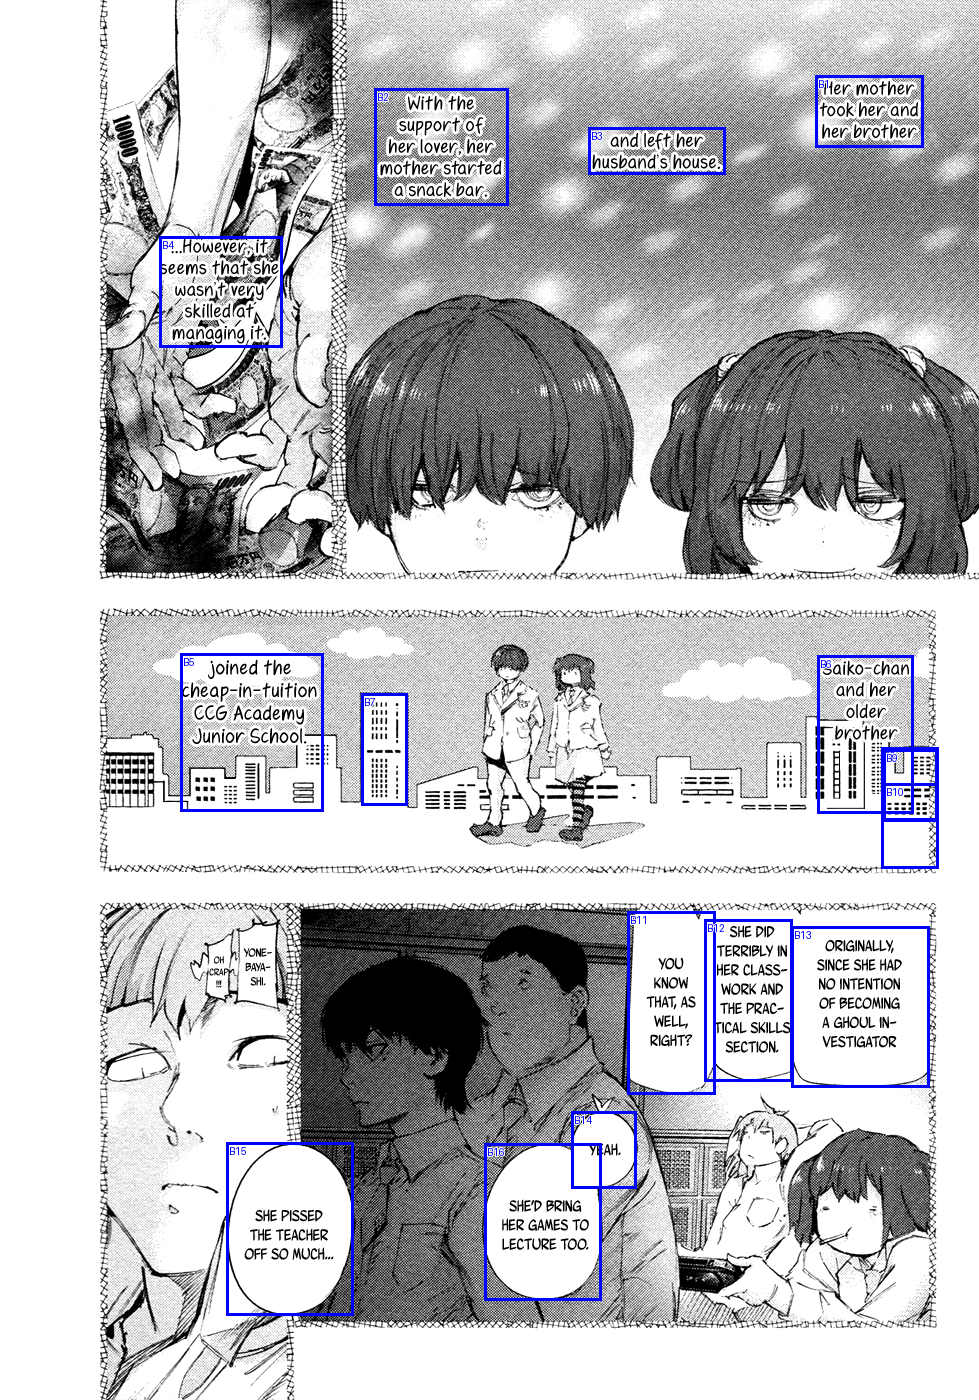

[{'box': [815, 75, 923, 147],
  'confidence': 0.9041560292243958,
  'bubble_id': 'B1'},
 {'box': [374, 88, 508, 205],
  'confidence': 0.8889814615249634,
  'bubble_id': 'B2'},
 {'box': [588, 127, 725, 174],
  'confidence': 0.8098385334014893,
  'bubble_id': 'B3'},
 {'box': [159, 236, 282, 347],
  'confidence': 0.8900741338729858,
  'bubble_id': 'B4'},
 {'box': [180, 653, 323, 811],
  'confidence': 0.660857081413269,
  'bubble_id': 'B5'},
 {'box': [817, 655, 913, 813],
  'confidence': 0.7006124258041382,
  'bubble_id': 'B6'},
 {'box': [361, 693, 407, 805],
  'confidence': 0.7370525002479553,
  'bubble_id': 'B7'},
 {'box': [881, 747, 938, 868],
  'confidence': 0.36618292331695557,
  'bubble_id': 'B8'},
 {'box': [883, 749, 937, 821],
  'confidence': 0.4458045959472656,
  'bubble_id': 'B9'},
 {'box': [883, 783, 937, 820],
  'confidence': 0.3256671130657196,
  'bubble_id': 'B10'},
 {'box': [627, 911, 715, 1094],
  'confidence': 0.8891035318374634,
  'bubble_id': 'B11'},
 {'box': [704, 919, 

In [3]:
preview = page.copy()
draw = ImageDraw.Draw(preview)
for bubble in bubbles:
    x1, y1, x2, y2 = bubble["box"]
    draw.rectangle((x1, y1, x2, y2), outline="blue", width=3)
    draw.text((x1 + 3, y1 + 3), bubble["bubble_id"], fill="blue", stroke_width=1, stroke_fill="white")
preview.save(OUT / "bubble_preview.png")
display(preview)
bubbles
